# Mosaic integration

In a mosaic design the batches do not all measure the same modalities. M3 still
puts every cell in one embedding.

Here two batches of the demo have RNA and ADT and the third has RNA only. The
tutorial uses the full demo (30,534 cells), like the patient-prediction and
attribution tutorials; training takes about 20 minutes on a laptop CPU. For a
quick look, `m3.datasets.liu_demo(n_cells=3000)` in step 0 brings that down to
about 3 minutes, with a less well resolved embedding.

In [1]:
import pandas as pd
import anndata as ad
import scanpy as sc
import matplotlib.pyplot as plt
import m3

sc.settings.verbosity = 1

## 0. Example files

This cell writes the demo as one `.h5ad` per batch and modality, leaving out the
ADT of batch `B3`. **Skip it when you have your own files.**

In [2]:
demo = m3.datasets.liu_demo()
obs = demo.obs.drop(columns="batch")
obs.index = [f"cell{i:05d}" for i in range(demo.n_cells)]          # cell barcodes

for b in ["B1", "B2", "B3"]:
    rows = (demo.obs["batch"] == b).to_numpy()
    for mod in ["rna", "adt"]:
        if (b, mod) != ("B3", "adt"):
            ad.AnnData(demo.modalities[mod][rows], obs=obs[rows],
                       var=pd.DataFrame(index=demo.var[mod])).write_h5ad(f"{b}_{mod}.h5ad")

## 1. Build each batch with the modalities it has

`B1` and `B2` have an RNA and an ADT file: keep the cells the two files share, in
one order, and pass both matrices to `m3.read_matrix`. `B3` has RNA only, so it
passes just that matrix. `m3.concat` then stacks the batches and marks the cells
of `B3` as having no ADT.

`batch=` names the batch because the example files have no `batch` column in
`obs`; if yours have one, that column is used instead.

In [3]:
batches = []

for b in ["B1", "B2"]:                                     # RNA and ADT
    rna = ad.read_h5ad(f"{b}_rna.h5ad")
    adt = ad.read_h5ad(f"{b}_adt.h5ad")
    cells = rna.obs_names.intersection(adt.obs_names)
    rna, adt = rna[cells], adt[cells]                      # same cells, same order
    obs = rna.obs.copy()
    obs["obs_names"] = rna.obs_names                       # to match results back
    batches.append(m3.read_matrix(
        counts={"rna": rna.X, "adt": adt.X},
        var={"rna": rna.var_names, "adt": adt.var_names},
        obs=obs, batch=b))

rna = ad.read_h5ad("B3_rna.h5ad")                          # RNA only: pass just that matrix
obs = rna.obs.copy()
obs["obs_names"] = rna.obs_names
batches.append(m3.read_matrix(
    counts={"rna": rna.X}, var={"rna": rna.var_names}, obs=obs, batch="B3"))

data = m3.concat(batches)
print(data)
print("cells measured:", {name: int(has.sum()) for name, has in data.present.items()})

Dataset(n_cells=30534, batches=['B1', 'B2', 'B3'], modalities=[adt:192, rna:1000])
cells measured: {'adt': 17952, 'rna': 30534}


`data.present` records, per cell, which modalities were measured. A batch can lack
any modality, RNA included: pass only the matrices it has. If a file holds all
batches, subset the AnnData by batch and build each batch the same way; for one
file with every batch and modality, see the last part of section 6 in
[Use your own data](https://pyanglab.github.io/M3/notebooks/py_05_own_data/).

Features are matched by name. If the batches do not have the same genes or
proteins, `m3.concat` keeps only those present in every batch that has the
modality, and warns with the numbers. `data.var["adt"]` and `data.var["rna"]`
list what was kept, so `set(adt.var_names) - set(data.var["adt"])` gives what a
batch lost.

## 2. Train

Training is the same call as for fully measured data.

In [4]:
model = m3.M3(data, condition_keys="cond_group", celltype_key="mergedcelltype")
model.train(donor_prediction=False)
print("capabilities:", model.capabilities)

Using 'matrix/data'
torch.Size([1000, 7163])
Using 'matrix/data'
torch.Size([1000, 10789])
Using 'matrix/data'
torch.Size([1000, 12582])
Using 'matrix/data'
torch.Size([192, 7163])
Using 'matrix/data'
torch.Size([192, 10789])
Batch counts: {np.int64(0): np.int64(7163), np.int64(1): np.int64(10789), np.int64(2): np.int64(12582)}
Minimum batch size: 7163
Epoch 1, Validation Loss: 4.1653
Epoch 2, Validation Loss: 4.1027
Epoch 3, Validation Loss: 4.0379
...  (294 epochs omitted)  ...
Epoch 298, Validation Loss: 0.5341
Epoch 299, Validation Loss: 0.5353
Epoch 300, Validation Loss: 0.5359
Using 'matrix/data'
torch.Size([1000, 7163])
Using 'matrix/data'
torch.Size([1000, 10789])
Using 'matrix/data'
torch.Size([1000, 12582])
Using 'matrix/data'
torch.Size([192, 7163])
Using 'matrix/data'
torch.Size([192, 10789])
capabilities: {'embedding': True, 'reconstruct': True, 'predict_donors': False}


## 3. One embedding for all cells

The embedding covers every cell, including the RNA-only batch. As in
[Use your own data](https://pyanglab.github.io/M3/notebooks/py_05_own_data/), it
goes back into an AnnData by the `obs_names` column of `model.cell_metadata`;
here that AnnData is the RNA of all batches.

`part="bio"` includes the condition factors, so cells also separate by
condition. `part="intrinsic"` leaves them out.

In [5]:
rna = ad.concat([ad.read_h5ad(f"{b}_rna.h5ad") for b in ["B1", "B2", "B3"]],
                keys=["B1", "B2", "B3"], label="batch")

emb = pd.DataFrame(model.embedding(part="bio"),
                   index=model.cell_metadata["obs_names"])
rna.obsm["X_m3"] = emb.loc[rna.obs_names].to_numpy()
print(rna)

AnnData object with n_obs × n_vars = 30534 × 1000
    obs: 'sample_id', 'Donor', 'cond_group', 'Age_interval', 'mergedcelltype', 'batch'
    obsm: 'X_m3'


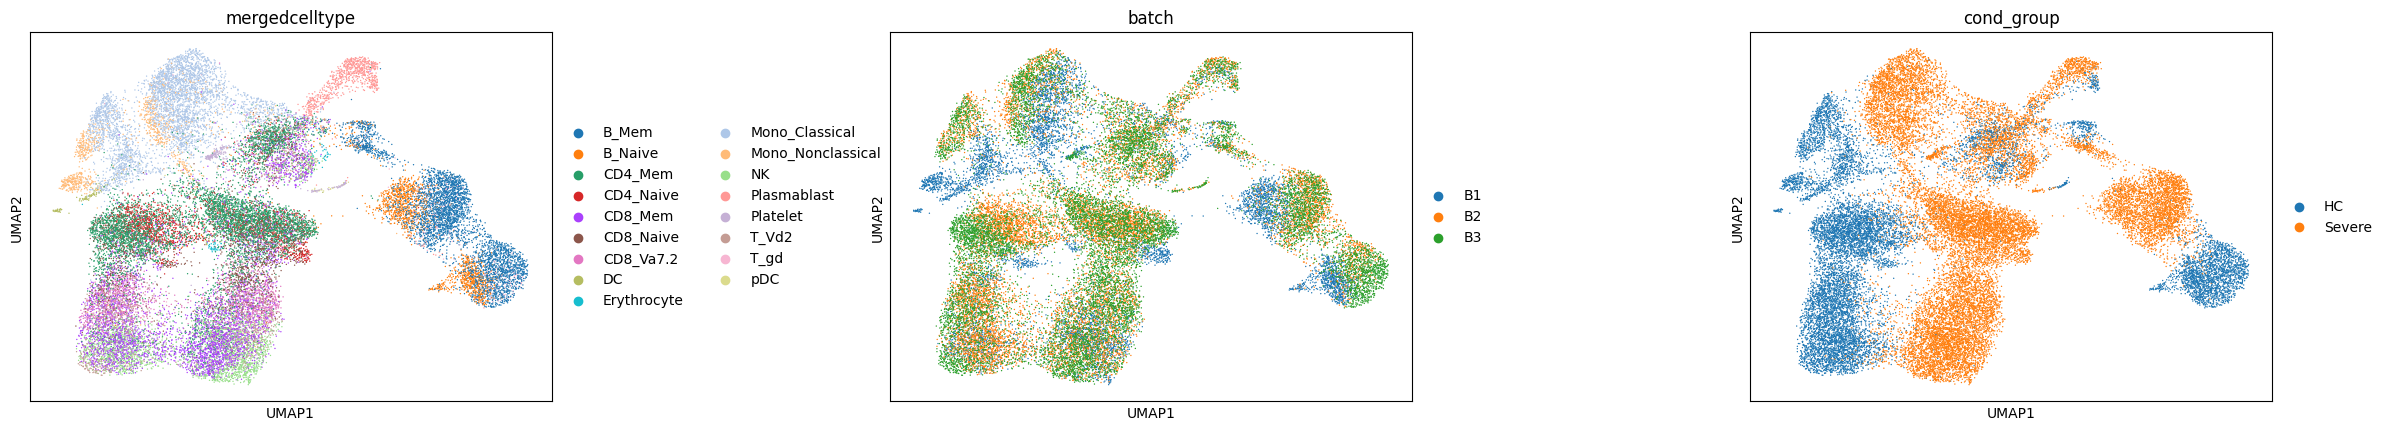

In [6]:
sc.pp.neighbors(rna, use_rep="X_m3", transformer="sklearn")
sc.tl.umap(rna)
sc.pl.umap(rna, color=["mergedcelltype", "batch", "cond_group"], wspace=0.5, show=False)
plt.savefig("umap_mosaic.png", dpi=130, bbox_inches="tight")
plt.show()

In [7]:
rna.write_h5ad("mosaic_m3.h5ad")